<div style="background:linear-gradient(135deg,#1b1448 0%,#3b1f5e 55%,#7c2d12 100%);border-radius:18px;padding:34px 30px;color:#fff;font-family:Inter,Segoe UI,sans-serif">
  <div style="font-size:12px;letter-spacing:3px;color:#fed7aa;font-weight:700;text-transform:uppercase">Chapter 3 · Tokens, context and cost</div>
  <div style="font-size:34px;font-weight:900;line-height:1.1;margin:10px 0 6px">Tokens, context and cost</div>
  <div style="font-size:15px;color:#ffe4d6;max-width:740px;line-height:1.6">Counting tokens before a request is sent, the context window a request has to fit, and the cost of a conversation as every turn resends its history.</div>
  <div style="font-size:13px;color:#fed7aa;margin-top:14px">Building AI with AI: A Visual Handbook · John Fisher</div>
</div>

A request is measured in tokens when it is counted before sending, when the API checks it against the model's context window, and when the response is billed. This notebook counts six versions of one support request with `count_tokens`, reads the context windows of Claude Haiku 5.5, Sonnet 5.5 and Opus 5.5 from the Models API, and runs a six-turn conversation on Claude Sonnet 5.5, reading what each turn cost. The prices and the arithmetic come from `tokencost.py`, which Claude Code generated from the chapter's spec and tests.

## Setup

This cell installs Anthropic's Python library and builds the client every call below goes through. It replays recorded answers unless you set `LIVE = True`.

In [1]:
# Set LIVE = True to send these requests to the Anthropic API with your own key, saved in
# Colab's secrets panel as ANTHROPIC_API_KEY. Left False, the notebook replays the answers
# recorded for the book, with no key and no cost.
LIVE = False
%pip install -q --disable-pip-version-check anthropic==2.7.0
import importlib, pathlib, sys, urllib.request
if "google.colab" in sys.modules:
    BASE = "https://raw.githubusercontent.com/johnfisher-ai/ai-with-ai/main/chapters/notebooks/"
    pathlib.Path("recordings").mkdir(exist_ok=True)
    for name in ["book_client.py", "recordings/tokens-context-and-cost.json"]:
        urllib.request.urlretrieve(BASE + name, name)
import book_client
importlib.reload(book_client)
client = book_client.make_client("tokens-context-and-cost", mode="live" if LIVE else None)

Note: you may need to restart the kernel to use updated packages.


Replaying 40 recorded responses from claude-haiku-5-5, claude-opus-5-5, claude-sonnet-5-5, recorded 2026-11-12. Set LIVE = True in Setup to call the API yourself.


## The module from the chapter's Claude Code build

The notebook's prices and arithmetic come from `tokencost.py`, which Claude Code generated in the chapter's build from a spec and 34 tests. The file lives in the book's repository, in `builds/tokens-context-and-cost/generated/`, next to the spec, the tests and a transcript of what Claude Code did. This cell loads it and prints its source, so the price table, `call_cost`, `context_check` and `project_conversation` are on the page before the notebook calls them. In Colab the cell downloads the file next to the notebook, and the Files panel on the left shows it.

In [2]:
# tokencost.py is the module Claude Code generated in this chapter's build, from the spec and tests in
# builds/tokens-context-and-cost/. Colab fetches it from the book's repository.
BUILD = "tokens-context-and-cost"
if "google.colab" in sys.modules:
    urllib.request.urlretrieve("https://raw.githubusercontent.com/johnfisher-ai/ai-with-ai/main/builds/"
                               f"{BUILD}/generated/tokencost.py", "tokencost.py")
else:
    sys.path.insert(0, str(pathlib.Path("../../builds", BUILD, "generated").resolve()))
import tokencost
tokencost = importlib.reload(tokencost)
from tokencost import PRICES, PRICES_AS_OF, call_cost, context_check, project_conversation, prompt_tokens

# The whole module, so you can read every function before the notebook uses it
import inspect
print(inspect.getsource(tokencost))

PRICES_AS_OF = "2026-11"

PRICES = {
    "claude-haiku-5-5": {"input": 0.10, "cache_write": 0.125, "cache_read": 0.01, "output": 0.50},
    "claude-sonnet-5-5": {"input": 2.00, "cache_write": 2.50, "cache_read": 0.10, "output": 10.00},
    "claude-opus-5-5": {"input": 4.00, "cache_write": 5.00, "cache_read": 0.20, "output": 20.00},
}

LONG_PROMPT_PRICES = {
    "claude-haiku-5-5": (
        100_000,
        {"input": 0.50, "cache_write": 0.625, "cache_read": 0.05, "output": 2.50},
    ),
}

_FIELDS = ("input_tokens", "output_tokens", "cache_read_input_tokens", "cache_creation_input_tokens")


def _counts(usage):
    out = {}
    for f in _FIELDS:
        if isinstance(usage, dict) or hasattr(usage, "get") and not hasattr(usage, f):
            v = usage.get(f)
        else:
            v = getattr(usage, f, None)
        v = 0 if v is None else v
        if v < 0:
            raise ValueError(f"{f} must not be negative")
        out[f] = v
    return out


def prompt_tokens(usage):
   

## Counting a request before it is sent

`count_tokens` takes the same model, messages, system prompt and tools as `messages.create` and returns the number of input tokens the request would use, without running the model. As of November 2026 it is free to call. The cell counts one support request written six ways, on all three models, and compares each count with a one-character request to separate the text from the request's fixed overhead.

In [3]:
MODEL = "claude-sonnet-5-5"
MODELS = ["claude-haiku-5-5", "claude-sonnet-5-5", "claude-opus-5-5"]

# One support request, written six ways
PAYLOADS = {
    "English": "My order arrived with a cracked screen. I'd like a replacement sent to the same address, please.",
    "JSON": '{"ticket_id": 48213, "channel": "email", "subject": "Cracked screen", "priority": "high"}',
    "CSV": "ticket_id,channel,subject,priority\n48213,email,Cracked screen,high\n48214,chat,Late delivery,low",
    "Python": ("def refund(order, amount):\n    if amount > order.total:\n"
               "        raise ValueError('too much')\n    return order.total - amount\n"),
    "German": ("Meine Bestellung kam mit einem gesprungenen Bildschirm an. "
               "Bitte senden Sie Ersatz an dieselbe Adresse."),
    "Japanese": "注文した商品の画面が割れて届きました。同じ住所に交換品を送ってください。",
}


def count(text, model=MODEL, **request):
    """Input tokens a request would use. count_tokens doesn't run the model and isn't billed."""
    return client.messages.count_tokens(model=model, messages=[{"role": "user", "content": text}],
                                        **request).input_tokens


# A one-character request shows the fixed cost of the request's format
BASE = {m: count(".", m) for m in MODELS}
counts = {name: {m: count(text, m) for m in MODELS} for name, text in PAYLOADS.items()}

print(f"one-character request: {BASE[MODEL]} input tokens")
print(f"{'payload':9} {'chars':>5} {'tokens':>6} {'beyond':>6} {'chars/token':>11}   same on all three models")
for name, text in PAYLOADS.items():
    n = counts[name][MODEL]
    beyond = n - BASE[MODEL]
    same = len(set(counts[name].values())) == 1
    print(f"{name:9} {len(text):>5} {n:>6} {beyond:>6} {len(text) / beyond:>11.2f}   {same}")

one-character request: 9 input tokens
payload   chars tokens beyond chars/token   same on all three models
English      96     38     29        3.31   True
JSON         89     47     38        2.34   True
CSV          95     50     41        2.32   True
Python      125     48     39        3.21   True
German      103     61     52        1.98   True
Japanese     36     39     30        1.20   True


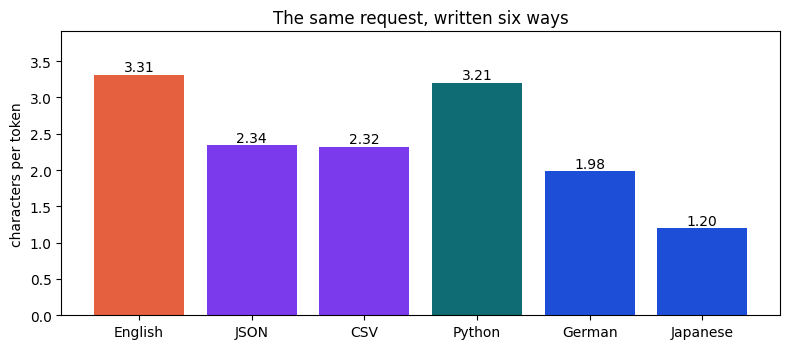

In [4]:
import matplotlib.pyplot as plt

names = list(PAYLOADS)
ratios = [len(PAYLOADS[n]) / (counts[n][MODEL] - BASE[MODEL]) for n in names]
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(names, ratios, color=["#e5603f", "#7c3aed", "#7c3aed", "#0f6b74", "#1d4ed8", "#1d4ed8"])
for bar, r in zip(bars, ratios):
    ax.text(bar.get_x() + bar.get_width() / 2, r + 0.05, f"{r:.2f}", ha="center", fontsize=10)
ax.set_ylabel("characters per token")
ax.set_ylim(0, max(ratios) + 0.6)
ax.set_title("The same request, written six ways", fontsize=12)
fig.tight_layout()
plt.show()

A one-character request already counts 9 input tokens, so the text of each payload is its count less 9. The English ticket averages 3.31 characters per token and the Python function 3.21. The same ticket as JSON or CSV drops to about 2.3, because braces, quotes, commas and field names each cost tokens. German takes 52 tokens for 103 characters, 1.98 per token, and the Japanese ticket 30 tokens for 36 characters, 1.20 per token. Claude Haiku 5.5, Sonnet 5.5 and Opus 5.5 returned the same count for every payload, so a budget measured on one of them carries over to the others.

## What a system prompt and a tool add

The text a user types is only one component of a request. A system prompt and every tool definition are sent as input on each call, and they are counted the same way.

In [5]:
SYSTEM = "You are a support assistant for an online electronics store. Answer in two or three sentences."
TOOL = {
    "name": "lookup_order",
    "description": "Look up an order by its number and return its items, status and delivery address.",
    "input_schema": {"type": "object", "properties": {"order_id": {"type": "integer"}},
                     "required": ["order_id"]},
}
TICKET = PAYLOADS["English"]

plain = count(TICKET)
with_system = count(TICKET, system=SYSTEM)
with_tool = count(TICKET, system=SYSTEM, tools=[TOOL])
print(f"the ticket alone:                 {plain} input tokens")
print(f"with the system prompt:           {with_system}  (+{with_system - plain})")
print(f"with the system prompt and a tool: {with_tool}  (+{with_tool - with_system} for one tool)")

the ticket alone:                 38 input tokens
with the system prompt:           65  (+27)
with the system prompt and a tool: 439  (+374 for one tool)


The system prompt, 16 words, added 27 tokens. One tool definition, with a name, a sentence of description and a one-field schema, added 374, more than the ticket and the system prompt together. Anthropic's pricing page lists 286 tokens for the instructions the API adds to any request that carries tools, on all three models as of November 2026, which leaves about 88 for the definition itself. Every definition a request carries is billed on every call, whether the model uses the tool or not.

## The context window holds the prompt and the reply

The Models API describes each model, including `max_input_tokens`, its context window, and `max_tokens`, the longest reply one request may generate. The window covers the whole request and the reply it produces, thinking included. `context_check` applies the API's rules as of November 2026. A prompt larger than the window is rejected, and a prompt that fits but leaves less room than `max_tokens` is accepted and stops early if the reply fills the window.

In [6]:
for m in MODELS:
    info = client.models.retrieve(m)
    print(f"{info.display_name:18} context window {info.max_input_tokens:>9,} tokens   "
          f"longest reply {info.max_tokens:>7,} tokens")

WINDOW_SIZE = client.models.retrieve(MODEL).max_input_tokens

# context_check applies the API's rules to a prompt size and a max_tokens setting
for prompt, max_tokens in [(with_tool, 1024), (900_000, 64_000), (950_000, 64_000), (1_000_001, 1024)]:
    print(f"prompt {prompt:>9,}  max_tokens {max_tokens:>6,}  ->  {context_check(prompt, max_tokens, WINDOW_SIZE)}")

Claude Haiku 5.5   context window 1,000,000 tokens   longest reply 128,000 tokens
Claude Sonnet 5.5  context window 1,000,000 tokens   longest reply 128,000 tokens
Claude Opus 5.5    context window 1,000,000 tokens   longest reply 128,000 tokens
prompt       439  max_tokens  1,024  ->  fits
prompt   900,000  max_tokens 64,000  ->  fits
prompt   950,000  max_tokens 64,000  ->  may stop early
prompt 1,000,001  max_tokens  1,024  ->  too long


All three models report a window of 1,000,000 tokens and a longest reply of 128,000. The 439-token request that carries a tool fits easily with `max_tokens` at 1,024, and so does a 900,000-token prompt with room for a 64,000-token reply. At 950,000 tokens the same reply may be cut off when the window fills, and a prompt of 1,000,001 tokens is refused before the model runs.

## A conversation resends its history

The Messages API keeps no state between calls, so each turn of a conversation sends every earlier message again. The cell runs six turns of a support conversation on Claude Sonnet 5.5. Before each call it counts the request, and afterward it reads the response's `usage`, the tokens the call was billed for. Each reply goes back into the history whole, its thinking block included, as the API expects.

In [7]:
TURNS = [
    "My order arrived with a cracked screen. What can I do?",
    "The order number is 48213. I'd prefer a replacement to a refund.",
    "How long will the replacement take to arrive?",
    "Can you send it to my office instead? It's 200 Market Street, Suite 4.",
    "Do I need to send the cracked one back first?",
    "Thanks. Can you summarize what happens next?",
]

history, log = [], []
for user_text in TURNS:
    history.append({"role": "user", "content": user_text})
    # count the request before it is sent, then send it and read what the response reports
    counted = client.messages.count_tokens(model=MODEL, system=SYSTEM, messages=history).input_tokens
    reply = client.messages.create(model=MODEL, max_tokens=1024, system=SYSTEM, messages=history)
    # the reply goes back into the history whole, thinking block included, as the API expects
    history.append({"role": "assistant", "content": reply.content})
    text = "".join(b.text for b in reply.content if b.type == "text")
    log.append({"counted": counted, "usage": reply.usage, "text": text})

print(f"{'turn':>4} {'counted':>8} {'billed in':>9} {'out':>4} {'thinking':>8} {'cost':>10}")
for i, entry in enumerate(log, 1):
    u = entry["usage"]
    print(f"{i:>4} {entry['counted']:>8} {u.input_tokens:>9} {u.output_tokens:>4} "
          f"{u.output_tokens_details.thinking_tokens:>8} {call_cost(u, MODEL):>10.6f}")
total = sum(call_cost(e["usage"], MODEL) for e in log)
print(f"six turns: {sum(e['usage'].input_tokens for e in log)} input tokens, "
      f"{sum(e['usage'].output_tokens for e in log)} output tokens, {total:.6f} dollars "
      f"at the prices as of {PRICES_AS_OF}")

turn  counted billed in  out thinking       cost
   1       53        53   88        0   0.000986
   2      166       166  249      103   0.002822
   3      432       432  154       38   0.002404
   4      617       617  115        0   0.002384
   5      750       750  149       44   0.002990
   6      919       919  200        0   0.003838
six turns: 2937 input tokens, 955 output tokens, 0.015424 dollars at the prices as of 2026-11


In [8]:
# What the model said on each turn
for i, entry in enumerate(log, 1):
    print(f"{i}. {entry['text']}\n")

1. I'm sorry your order arrived damaged! Please take clear photos of the cracked screen and the packaging, then contact us with your order number so we can start a replacement or refund. Avoid throwing away the box and packing materials, as we may need them for the claim or carrier return.

2. Thanks for the order number, and I'm sorry for the hassle. I can't access order details or issue the replacement from this chat, so please send your photos of the screen and packaging, along with order #48213 and a note that you'd like a replacement, to our support team through the "Returns & Damage Claims" form or by replying to your order confirmation email. Keep the box and packing materials until the replacement is arranged, since the carrier may need them for pickup or inspection.

3. I can't give you an exact date, since I don't have access to our replacement timelines or your order's details. Typically, a claim is reviewed first, and then the replacement ships, so the total time depends on

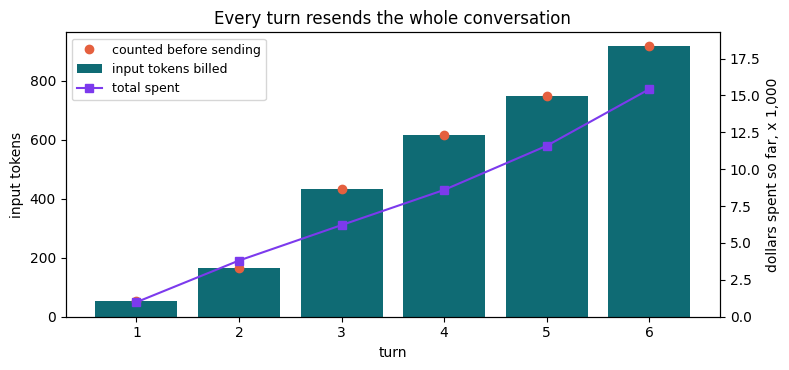

In [9]:
import itertools

turn = range(1, len(log) + 1)
billed = [e["usage"].input_tokens for e in log]
counted = [e["counted"] for e in log]
spent = list(itertools.accumulate(call_cost(e["usage"], MODEL) * 1000 for e in log))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(turn, billed, color="#0f6b74", label="input tokens billed")
ax.plot(turn, counted, "o", color="#e5603f", label="counted before sending")
ax.set_xlabel("turn")
ax.set_ylabel("input tokens")
ax2 = ax.twinx()
ax2.plot(turn, spent, color="#7c3aed", marker="s", label="total spent")
ax2.set_ylabel("dollars spent so far, x 1,000")
ax2.set_ylim(0, max(spent) * 1.25)
lines = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax.legend(lines, [l.get_label() for l in lines], loc="upper left", fontsize=9)
ax.set_title("Every turn resends the whole conversation", fontsize=12)
fig.tight_layout()
plt.show()

`count_tokens` matched the billed input exactly on all six turns, from 53 tokens on the first to 919 on the sixth. Turn 2's prompt was 113 tokens larger than turn 1's, the first reply's 88 tokens plus 25 for the second question. The second reply wrote 249 output tokens, 103 of them thinking, and the third prompt grew by 266, so those thinking tokens came back as input on the next turn although the reply showed none of their text. Six turns read 2,937 input tokens and wrote 955, for 0.015424 dollars at the prices as of November 2026.

## Projecting a longer conversation

`project_conversation` extends the measured pattern. The prompt grew by about 173 tokens a turn and the replies averaged about 159 output tokens, so a longer conversation can be priced before anyone has it.

In [10]:
# The measured conversation, extended with the calculator. Each turn added about the same number of tokens.
growth = [b - a for a, b in zip(billed, billed[1:])]
added = round(sum(growth) / len(growth))
output = round(sum(e["usage"].output_tokens for e in log) / len(log))
print(f"growth per turn: {growth}, about {added} tokens; about {output} output tokens a reply")

for turns in [6, 12, 30]:
    projected = project_conversation(billed[0], added, output, turns)
    cost = sum(call_cost(t, MODEL) for t in projected)
    print(f"{turns:>2} turns: last prompt {projected[-1]['input_tokens']:>6,} tokens, "
          f"{sum(t['input_tokens'] for t in projected):>7,} input tokens in all, {cost:.4f} dollars")

growth per turn: [113, 266, 185, 133, 169], about 173 tokens; about 159 output tokens a reply
 6 turns: last prompt    918 tokens,   2,913 input tokens in all, 0.0154 dollars
12 turns: last prompt  1,956 tokens,  12,054 input tokens in all, 0.0432 dollars
30 turns: last prompt  5,070 tokens,  76,845 input tokens in all, 0.2014 dollars


The projection comes close to the six measured turns, 2,913 input tokens against the 2,937 billed, at 0.0154 dollars. Twelve turns read 12,054 input tokens for 0.0432 dollars, nearly three times the cost of six, and thirty turns read 76,845 for 0.2014 dollars. Total input grows with the square of the number of turns, because each turn resends all the turns before it.

## Pricing a workload

A cost per call becomes a budget once it is multiplied by traffic. The first cell prices a thousand of the measured conversations a day for thirty days on each model, keeping the token counts fixed, and the second shows the one place where the size of a prompt changes the price per token.

In [11]:
# A thousand six-turn conversations a day for thirty days, with the measured token counts on each model.
# All three models counted the payloads identically, so the input carries over. The output is Sonnet's,
# and another model may write more or less.
CONVERSATIONS = 1_000 * 30
for m in MODELS:
    month = CONVERSATIONS * sum(call_cost(e["usage"], m) for e in log)
    print(f"{m:18} {month:>8.2f} dollars a month")

claude-haiku-5-5      23.14 dollars a month
claude-sonnet-5-5    462.72 dollars a month
claude-opus-5-5      925.44 dollars a month


In [12]:
# Claude Haiku 5.5 charges more once a prompt passes 100,000 tokens, on every token of that request
for prompt in [100_000, 100_001]:
    usage = {"input_tokens": prompt, "output_tokens": 1_000}
    print(f"{prompt:,} input tokens and 1,000 output tokens: {call_cost(usage, 'claude-haiku-5-5'):.4f} dollars")

100,000 input tokens and 1,000 output tokens: 0.0105 dollars
100,001 input tokens and 1,000 output tokens: 0.0525 dollars


At the prices as of November 2026, the month of conversations costs 23.14 dollars on Claude Haiku 5.5, 462.72 on Sonnet 5.5 and 925.44 on Opus 5.5. The input counts carry over between models, as the counts above showed, but the output is Sonnet's, so the other two figures hold only if those models write replies of the same length, which Chapter 117, Choosing a model, measures. Claude Haiku 5.5 charges five times as much for a request whose prompt is over 100,000 tokens, on every token of that request, so one token past the threshold raises the call from 0.0105 to 0.0525 dollars.

## What the notebook showed

- `count_tokens` predicted the billed input of all six turns exactly, at no cost.
- Characters per token ranged from 3.31 for the English ticket to 1.20 for the Japanese one, and the three models counted every payload the same.
- The system prompt cost 27 tokens and one tool definition 374, on every call.
- Each model's window holds 1,000,000 tokens, prompt and reply together, with replies capped at 128,000.
- A conversation's input grows with every turn, thinking tokens included, so twelve turns cost nearly three times as much as six.

---
<div style="text-align:center;color:#666f8e;font-size:12px;margin-top:10px">Building AI with AI: A Visual Handbook · © 2026 John Fisher · text CC BY 4.0, code MIT</div>